# Лабораторная работа №1
## Низкоуровневый анализ, предобработка текста и статистическое языковое моделирование

**Датасет:** [Enron Email Dataset](https://www.kaggle.com/datasets/wcukierski/enron-email-dataset): около 517 тыс. писем сотрудников Enron, файл `emails.csv` с колонками `file` и `message`.

**Подготовка:** скачайте архив с Kaggle и положите `emails.csv` в `labs/lab1/data/emails.csv` (папка `data/` в `.gitignore`).

План (пункты задания):
1. Загрузка, выделение текстовой колонки и целевого класса, стратифицированный сплит 80/20.
2. EDA на train: число документов, длины текстов, распределения, топ-30 стоп-слов.
3. Поиск доменного шума с количественными доказательствами.
4. Конвейер очистки на `re`, отдельное правило на каждый тип шума, токены `<s>`/`</s>`.
5. Стемминг и лемматизация: сравнение размеров словарей.
6. Собственный Левенштейн (O(min(n, m)) по памяти) и поиск опечаток.
7. N-граммная модель (N = 2 и N = 3) с явным словарём и `[UNK]`.
8. Сглаживание (add-k и интерполированный Кнезер–Ней), перплексия через log-likelihood.
9. Генерация 5 текстов марковской цепью.

In [1]:
import email
import html
import math
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import nltk

for pkg in ["stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk.tag import PerceptronTagger

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_PATH = Path("data/emails.csv")
# Полный корпус (517k писем) слишком тяжёл для pos-теггинга и python-словарей n-грамм,
# поэтому берём случайную подвыборку. None = весь корпус.
SAMPLE_SIZE = 60_000

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
})
BAR_COLOR = "#3b6ea8"

Matplotlib is building the font cache; this may take a moment.


## 1. Загрузка данных и стратифицированное разбиение

В `message` лежит **сырое письмо целиком**: SMTP-заголовки (`Message-ID`, `X-From`, `X-FileName`…) и тело. Целевая текстовая колонка — **тело письма** (`body`). Его достаём стандартным модулем `email`, а заголовки отбрасываем: это метаданные, а не естественный язык.

**Целевой класс.** Готовой разметки в Enron нет, поэтому класс выводим из пути `file` (`allen-p/_sent_mail/1.` → папка `_sent_mail`). Папки сводим к 5 классам:
* `sent`: `sent`, `_sent_mail`, `sent_items` (письма, написанные владельцем ящика);
* `inbox`: `inbox`, `notes_inbox`;
* `deleted`: `deleted_items`;
* `auto_archive`: `all_documents`, `discussion_threads` (автоматические представления Lotus Notes, в основном копии других папок);
* `user_folders`: всё остальное (пользовательские папки).

**Дубликаты.** Одно и то же письмо лежит у отправителя (`sent`), у получателя (`inbox`) и в `all_documents`. Если не убрать дубли **до** разбиения, одинаковые тексты попадут и в train, и в test, и перплексия окажется заниженной (утечка). Дедуплицируем по нормализованному телу и оставляем копию из самой «информативной» папки по приоритету `sent > inbox > deleted > user_folders > auto_archive`.

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("wcukierski/enron-email-dataset", output_dir="data/")

print("Path to dataset files:", path)

100%|██████████| 358M/358M [00:33<00:00, 11.2MB/s] 

Extracting files...


Path to dataset files: data/


In [9]:
df_raw = pd.read_csv(DATA_PATH)
print("Всего писем в файле:", len(df_raw))
print(df_raw.columns.tolist())
if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df_raw):
    df_raw = df_raw.sample(n=SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)
print("Взято в работу:", len(df_raw))
print(df_raw.iloc[0]["message"][:800])

Всего писем в файле: 517401
['file', 'message']
Взято в работу: 60000
Message-ID: <21013688.1075844564560.JavaMail.evans@thyme>
Date: Tue, 29 Aug 2000 01:26:00 -0700 (PDT)
From: sara.shackleton@enron.com
To: william.bradford@enron.com
Subject: Re: Credit Derivatives
Mime-Version: 1.0
Content-Type: text/plain; charset=us-ascii
Content-Transfer-Encoding: 7bit
X-From: Sara Shackleton
X-To: William S Bradford
X-cc: 
X-bcc: 
X-Folder: \Sara_Shackleton_Dec2000_June2001_1\Notes Folders\Sent
X-Origin: SHACKLETON-S
X-FileName: sshackle.nsf

Bill:  Thanks for the info.   I also spoke with Jeff about how 
EnronCredit.com Ltd. was going to work since Dennis O'Connell (London lawyer) 
is responsible for that group.  Maybe you will be able to clarify which of 
Jeff's "positions" will be hedges and which will be backed to EnronCredit.  
Maybe Rod will be handling most of J


In [10]:
SENT = {"sent", "_sent_mail", "sent_items"}
INBOX = {"inbox", "notes_inbox"}
AUTO = {"all_documents", "discussion_threads"}
CLASS_PRIORITY = {"sent": 0, "inbox": 1, "deleted": 2, "user_folders": 3, "auto_archive": 4}


def folder_class(path: str) -> str:
    parts = path.split("/")
    folder = parts[1].lower() if len(parts) > 2 else "root"
    if folder in SENT:
        return "sent"
    if folder in INBOX:
        return "inbox"
    if folder == "deleted_items":
        return "deleted"
    if folder in AUTO:
        return "auto_archive"
    return "user_folders"


def extract_body(raw: str) -> str:
    """Тело письма без SMTP-заголовков (поддержка multipart на всякий случай)."""
    msg = email.message_from_string(raw)
    if msg.is_multipart():
        parts = [p.get_payload() for p in msg.walk()
                 if p.get_content_type() == "text/plain" and not p.is_multipart()]
        return "\n".join(str(p) for p in parts)
    return str(msg.get_payload())


df = pd.DataFrame({
    "file": df_raw["file"],
    "label": df_raw["file"].map(folder_class),
    "body": df_raw["message"].map(extract_body),
})
del df_raw

df["dedup_key"] = df["body"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["dedup_key"].str.len() > 0]
n_before = len(df)
df["prio"] = df["label"].map(CLASS_PRIORITY)
df = (df.sort_values("prio", kind="stable")
        .drop_duplicates("dedup_key", keep="first")
        .drop(columns=["prio", "dedup_key"])
        .reset_index(drop=True))
print(f"Удалено пустых/дубликатов: {n_before - len(df)} из {n_before}; осталось {len(df)}")
print(df["label"].value_counts())

Удалено пустых/дубликатов: 7578 из 60000; осталось 52422
label
auto_archive    16610
sent            14346
inbox            8789
user_folders     7563
deleted          5114
Name: count, dtype: int64


In [11]:
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

dist = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "test": test_df["label"].value_counts(normalize=True),
}).round(4)
print(f"Train: {len(train_df)}, Test: {len(test_df)}")
dist  # доли классов совпадают, значит стратификация сработала

Train: 41937, Test: 10485


,train,test
label,,
auto_archive,0.3169,0.3168
sent,0.2737,0.2736
inbox,0.1677,0.1677
user_folders,0.1443,0.1443
deleted,0.0976,0.0976


## 2. Исследование структуры данных (только train)

In [12]:
train_df["n_chars"] = train_df["body"].str.len()
train_df["n_words"] = train_df["body"].str.split().str.len()

summary = pd.DataFrame({
    "Документов": [len(train_df)],
    "Ср. длина, слов": [train_df["n_words"].mean()],
    "Медиана, слов": [train_df["n_words"].median()],
    "Ср. длина, символов": [train_df["n_chars"].mean()],
    "Медиана, символов": [train_df["n_chars"].median()],
    "95-й перц., слов": [train_df["n_words"].quantile(0.95)],
    "Макс., слов": [train_df["n_words"].max()],
}).round(1)
summary

,Документов,"Ср. длина, слов","Медиана, слов","Ср. длина, символов","Медиана, символов","95-й перц., слов","Макс., слов"
0,41937,266.0,113.0,1848.6,758.0,857.0,37116


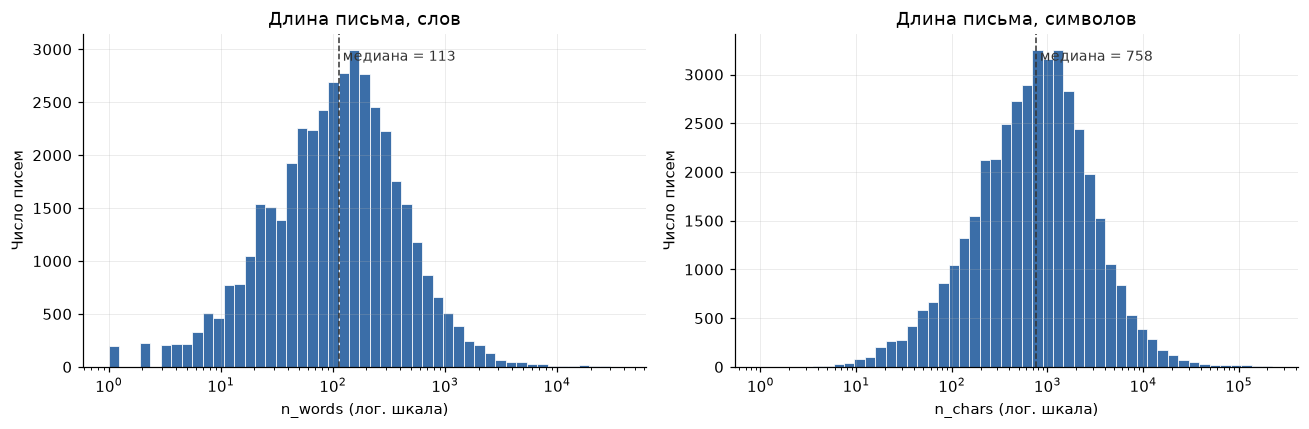

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "n_words", "Длина письма, слов"),
                       (axes[1], "n_chars", "Длина письма, символов")]:
    vals = train_df[col].clip(lower=1)
    bins = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 50)
    ax.hist(vals, bins=bins, color=BAR_COLOR, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    ax.axvline(vals.median(), color="#333", linestyle="--", linewidth=1)
    ax.text(vals.median(), ax.get_ylim()[1] * 0.92, f" медиана = {vals.median():.0f}",
            fontsize=9, color="#333")
    ax.set_title(title)
    ax.set_xlabel(col + " (лог. шкала)")
    ax.set_ylabel("Число писем")
plt.tight_layout()
plt.show()

Распределение длин сильно скошено вправо, поэтому ось X логарифмическая. Хвост дают письма с пересланными цепочками, вставленными отчётами и таблицами. Средняя длина заметно больше медианы, и для таких данных медиана — более честная характеристика.

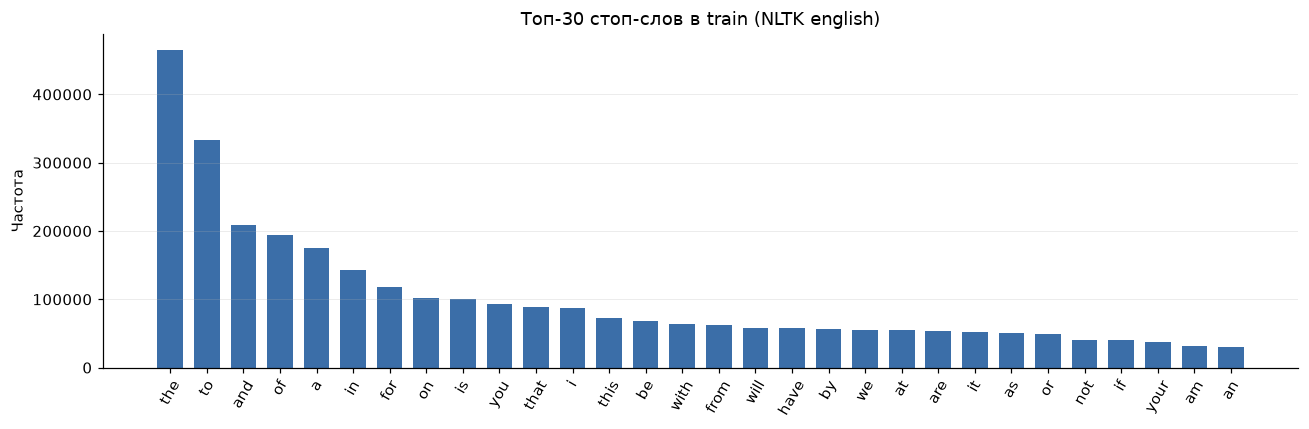

Доля стоп-слов среди всех словоформ: 35.5%


In [14]:
STOP = set(stopwords.words("english"))
simple_tok = re.compile(r"[a-z]+(?:'[a-z]+)?")

stop_counter = Counter()
for text in train_df["body"]:
    for t in simple_tok.findall(text.lower()):
        if t in STOP:
            stop_counter[t] += 1

top_stop = stop_counter.most_common(30)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([w for w, _ in top_stop], [c for _, c in top_stop], color=BAR_COLOR, width=0.7)
ax.set_title("Топ-30 стоп-слов в train (NLTK english)")
ax.set_ylabel("Частота")
plt.xticks(rotation=60)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

total_tokens = sum(len(simple_tok.findall(t.lower())) for t in train_df["body"])
print(f"Доля стоп-слов среди всех словоформ: {sum(stop_counter.values()) / total_tokens:.1%}")

## 3. Доменный шум

Шум в корпоративной почте устроен иначе, чем в твитах. Проверяем гипотезы регулярными выражениями и для каждого типа считаем долю писем в train, где он встречается, плюс пример. Нулевая доля для паттерна — доказательство того, что этого шума в данных нет.

In [15]:
NOISE_PATTERNS = {
    "Цитаты/пересылки (Original Message, Forwarded by)":
        r"-{2,}\s*Original Message\s*-{2,}|-{3,}\s*Forwarded by",
    "Заголовки вложенных писем (From:/To:/Subject:/cc:)":
        r"(?m)^\s*(?:From|To|Subject|Sent|cc|bcc)\s*:",
    "Цитирование строк символом '>'": r"(?m)^\s*>",
    "Lotus Notes адреса (Name/HOU/ECT@ECT)": r"\b\w+/[A-Z]{2,6}(?:/[A-Z]{2,6})*@[A-Z]{2,6}\b",
    "E-mail адреса": r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b",
    "URL": r"(?i)\b(?:https?://|www\.)\S+",
    "Quoted-printable артефакты (=20, =09, =\\n)": r"=(?:20|09|3D)|=\r?\n",
    "HTML-теги": r"</?[a-zA-Z][^>]{0,200}>",
    "HTML-сущности (&nbsp; &amp;)": r"&(?:nbsp|amp|lt|gt|quot|#\d+);",
    "Линии-разделители (----, ****, ____)": r"[-=*_~#]{5,}",
    "Даты (10/23/2000)": r"\b\d{1,2}/\d{1,2}/\d{2,4}\b",
    "Время (08:53 AM)": r"\b\d{1,2}:\d{2}(?::\d{2})?\s*(?:[AaPp]\.?[Mm]\.?)?",
    "Телефоны": r"\(?\b\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}\b",
    "Денежные суммы ($1,000)": r"\$\s?\d[\d,]*(?:\.\d+)?(?:\s?(?:mm|k|million|billion))?",
    "Числа": r"\b\d+(?:[.,]\d+)*\b",
    "Смайлики :) ;-)": r"(?<!\w)[:;=][-']?[)(DPp](?!\w)",
}

rows = []
for name, pat in NOISE_PATTERNS.items():
    rx = re.compile(pat)
    has = train_df["body"].map(lambda t: bool(rx.search(t)))
    n_matches = train_df["body"].map(lambda t: len(rx.findall(t))).sum()
    example = ""
    for t in train_df.loc[has, "body"].head(50):
        m = rx.search(t)
        if m:
            s, e = max(m.start() - 25, 0), min(m.end() + 25, len(t))
            example = t[s:e].replace("\n", "⏎")
            break
    rows.append({"Тип шума": name, "Доля писем": has.mean(),
                 "Всего вхождений": int(n_matches), "Пример (контекст)": example})

noise_df = pd.DataFrame(rows).sort_values("Доля писем", ascending=False)
pd.set_option("display.max_colwidth", 90)
noise_df.style.format({"Доля писем": "{:.1%}"})

,Тип шума,Доля писем,Всего вхождений,Пример (контекст)
14,Числа,81.1%,864906,"vations planned for TW L-154 line, I will will miss t"
11,Время (08:53 AM),50.9%,65428,"Thursday, April 26, 2001 4:45 PM⏎To: Ray, Tess⏎Cc: Farmer"
1,Заголовки вложенных писем (From:/To:/Subject:/cc:),43.6%,115981,"---Original Message-----⏎From: Ellenberger, Mary ⏎Sen"
9,"Линии-разделители (----, ****, ____)",41.0%,68521,he info that you need?⏎⏎ -----Original Message-----⏎Fro
10,Даты (10/23/2000),38.1%,47728,Ray/ENRON@enronXgate on 04/26/2001 03:48 PM⏎To: Mary Ellenb
0,"Цитаты/пересылки (Original Message, Forwarded by)",34.4%,24463,"he info that you need?⏎⏎ -----Original Message-----⏎From: Ellenberger, Mary"
4,E-mail адреса,31.1%,89683,": ""Trochta, Mary (ML)"" <MLTrochta@dow.com <mailto:MLTrochta@dow.co"
12,Телефоны,23.3%,22097,ue Mara⏎Enron Corp.⏎Tel: (415) 782-7802⏎Fax:(415) 782-7854⏎
3,Lotus Notes адреса (Name/HOU/ECT@ECT),18.0%,45789,"o: Ray, Tess⏎Cc: Daren J Farmer/HOU/ECT@ENRON; Bellamy, Liz⏎Subject: R"
7,HTML-теги,16.0%,97850,"m: ""Trochta, Mary (ML)"" >@ENRON [mailto:IMCEANOTE"


**Выводы по шуму** (точные доли видны в таблице выше):
1. **Цитаты и пересылки** — главный шум домена. Ответы содержат историю переписки (`-----Original Message-----`, `---- Forwarded by …`, блоки `From:/To:/Subject:`). Этот текст повторяет **чужие** письма, которые уже есть в корпусе, поэтому он дублирует данные и создаёт утечку между train и test. Решение: отрезать всё, начиная с маркера цитаты.
2. **Адреса**: обычные e-mail и внутренний формат Lotus Notes `Phillip K Allen/HOU/ECT@ECT`. Они почти уникальны и раздувают словарь, поэтому заменяем на `[EMAIL]`.
3. **Артефакты кодировки quoted-printable** (`=20`, `=09`, мягкие переносы `=` в конце строки) и **HTML** (теги, `&nbsp;`). Это технический мусор транспорта, его декодируем или вырезаем.
4. **Линии-разделители** из `-`, `*`, `_`, `=` не несут смысла и удаляются.
5. **Числа, даты, время, телефоны, суммы.** Значения уникальны, но сам факт их наличия важен для деловой переписки («meet at [TIME]», «price is [MONEY]»), поэтому заменяем на классовые токены.
6. Смайлики встречаются редко: в деловой почте 2000–2001 годов их почти нет, это видно по доле в таблице. Отдельно не обрабатываются.

## 4. Конвейер очистки

Каждое правило отвечает за свой тип шума. Порядок важен:
* сначала отрезаем цитаты (иначе дальше будем чистить чужой текст);
* декодируем quoted-printable и HTML **до** поиска URL/адресов (`=\n` может разрывать URL);
* адреса Lotus Notes ищем **до** приведения к нижнему регистру (паттерн опирается на `HOU/ECT`);
* даты, время и телефоны заменяем **до** общего правила для чисел, иначе `10/23/2000` превратится в `[NUM]/[NUM]/[NUM]`.

Токенизация оставляет слова (с апострофом: `don't`, `enron's`), спецтокены и знаки конца предложения `. , ! ?`: они нужны языковой модели, чтобы генерировать читаемый текст.

In [16]:
SPECIAL_TOKENS = ["[URL]", "[EMAIL]", "[PHONE]", "[MONEY]", "[DATE]", "[TIME]", "[NUM]"]
BOS, EOS, UNK = "<s>", "</s>", "[UNK]"

RE_QUOTE_START = re.compile(
    r"-{2,}\s*Original Message\s*-{2,}"                 # Outlook
    r"|-{3,}\s*Forwarded by"                            # Lotus Notes forward
    r"|\n[^\n]*\n?\s*\d{1,2}/\d{1,2}/\d{2,4}\s+\d{1,2}:\d{2}\s*[AP]M\s*\n\s*To:"  # Lotus reply header
    r"|\n\s*From:\s[^\n]*\n\s*(?:Sent|To|Date):"        # вложенный заголовок
    r"|\n\s*To:\s[^\n]*\n\s*cc:",                        # Lotus: To/cc блок
    re.IGNORECASE,
)
RE_QUOTED_LINE = re.compile(r"(?m)^\s*>.*$")
RE_QP_SOFTBREAK = re.compile(r"=\r?\n")
RE_QP_CODES = re.compile(r"=(20|09|3D)")
RE_HTML_TAG = re.compile(r"</?[a-zA-Z][^>]{0,200}>")
RE_URL = re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>\"]+")
RE_EMAIL = re.compile(r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b")
RE_NOTES_ADDR = re.compile(r"\b[\w.-]+/[A-Z]{2,6}(?:/[A-Z]{2,6})*@[A-Z]{2,6}\b")
RE_SEPARATOR = re.compile(r"[-=*_~#+]{3,}")
RE_PHONE = re.compile(r"\(?\b\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}\b")
RE_MONEY = re.compile(r"\$\s?\d[\d,]*(?:\.\d+)?(?:\s?(?:mm|k|million|billion)\b)?", re.I)
RE_DATE = re.compile(r"\b\d{1,2}/\d{1,2}/\d{2,4}\b|\b\d{4}-\d{2}-\d{2}\b")
RE_TIME = re.compile(r"\b\d{1,2}:\d{2}(?::\d{2})?(?:\s*[ap]\.?m\.?\b)?", re.I)
RE_NUM = re.compile(r"\b\d+(?:[.,]\d+)*(?:st|nd|rd|th|%)?")
RE_REPEAT_PUNCT = re.compile(r"([!?.,])\1+")
RE_SPACES = re.compile(r"\s+")
RE_SPECIAL_LOWER = re.compile(r"\[(url|email|phone|money|date|time|num)\]")
RE_TOKEN = re.compile(r"\[(?:URL|EMAIL|PHONE|MONEY|DATE|TIME|NUM)\]|[a-z][a-z0-9]*(?:'[a-z]+)?|[.!?,]")


def clean_text(text: str) -> str:
    # 1) цитаты и пересылки: отрезаем хвост, начиная с первого маркера
    m = RE_QUOTE_START.search(text)
    if m:
        text = text[: m.start()]
    text = RE_QUOTED_LINE.sub(" ", text)
    # 2) quoted-printable
    text = RE_QP_SOFTBREAK.sub("", text)
    text = RE_QP_CODES.sub(lambda m: {"20": " ", "09": " ", "3D": "="}[m.group(1)], text)
    # 3) HTML
    text = RE_HTML_TAG.sub(" ", text)
    text = html.unescape(text).replace("\xa0", " ")
    # 4) URL и адреса (до разделителей: в URL бывают '___')
    text = RE_URL.sub(" [URL] ", text)
    text = RE_EMAIL.sub(" [EMAIL] ", text)
    text = RE_NOTES_ADDR.sub(" [EMAIL] ", text)
    # 5) разделители
    text = RE_SEPARATOR.sub(" ", text)
    # 6) числовые сущности: от частного к общему
    text = RE_PHONE.sub(" [PHONE] ", text)
    text = RE_MONEY.sub(" [MONEY] ", text)
    text = RE_DATE.sub(" [DATE] ", text)
    text = RE_TIME.sub(" [TIME] ", text)
    text = RE_NUM.sub(" [NUM] ", text)
    # 7) нижний регистр с сохранением спецтокенов, повторы пунктуации, пробелы
    text = RE_SPECIAL_LOWER.sub(lambda m: m.group(0).upper(), text.lower())
    text = RE_REPEAT_PUNCT.sub(r"\1", text)
    return RE_SPACES.sub(" ", text).strip()


def tokenize(clean: str) -> list:
    return RE_TOKEN.findall(clean)


def preprocess(text: str) -> list:
    """Полный конвейер: очистка, токенизация, <s> ... </s>."""
    return [BOS] + tokenize(clean_text(text)) + [EOS]


demo = (
    "Phillip,\n\nPlease check http://www.enron.com/gas?id=3D12 and call me at 713-853-7041 "
    "before 10:30 AM on 10/23/2000.  The price is $1,250.50 for 3 units!!!\n"
    "Thanks=20\nJohn Arnold/HOU/ECT@ECT\n\n"
    "---------------------- Forwarded by Phillip K Allen/HOU/ECT on 10/23/2000 08:53 AM ---\n"
    "old quoted text that must disappear"
)
print(clean_text(demo))
print(preprocess(demo))

phillip, please check [URL] and call me at [PHONE] before [TIME] on [DATE] . the price is [MONEY] for [NUM] units! thanks john [EMAIL]
['<s>', 'phillip', ',', 'please', 'check', '[URL]', 'and', 'call', 'me', 'at', '[PHONE]', 'before', '[TIME]', 'on', '[DATE]', '.', 'the', 'price', 'is', '[MONEY]', 'for', '[NUM]', 'units', '!', 'thanks', 'john', '[EMAIL]', '</s>']


In [17]:
for d in (train_df, test_df):
    d["clean"] = d["body"].map(clean_text)
    d["tokens"] = d["clean"].map(lambda s: [BOS] + tokenize(s) + [EOS])
    d["n_tok"] = d["tokens"].str.len() - 2

# Письма, где после очистки не осталось текста (чистые пересылки без комментария,
# только подпись), не несут собственного текста автора и для модели бесполезны.
MIN_TOKENS = 3
for name in ("train_df", "test_df"):
    d = globals()[name]
    before = len(d)
    globals()[name] = d[d["n_tok"] >= MIN_TOKENS].reset_index(drop=True)
    print(f"{name}: удалено {before - len(globals()[name])} пустых после очистки, осталось {len(globals()[name])}")

for i in range(3):
    print("-" * 80)
    print("RAW:  ", train_df.loc[i, "body"][:300].replace("\n", " ⏎ "))
    print("CLEAN:", " ".join(train_df.loc[i, "tokens"][:60]))

train_df: удалено 4799 пустых после очистки, осталось 37138
test_df: удалено 1182 пустых после очистки, осталось 9303
--------------------------------------------------------------------------------
RAW:   As I will be out of town at Gallup NM this week for the excavations planned for TW L-154 line, I will will miss the the meeting on the 10th. ⏎  ⏎ I have begun preparation of a cost estimate for the above, given it is very rough and I am awaiting information from Facility Planning which should fine tune 
CLEAN: <s> as i will be out of town at gallup nm this week for the excavations planned for tw l [NUM] line , i will will miss the the meeting on the [NUM] . i have begun preparation of a cost estimate for the above , given it is very rough and i am awaiting information from facility planning which
--------------------------------------------------------------------------------
RAW:   Thanks Mary! ⏎ Daren, is the info that you need? ⏎  ⏎  -----Original Message----- ⏎ From: 	Ellenberger

In [18]:
tok_counter = Counter(t for toks in train_df["tokens"] for t in toks)
print("Токенов в train после очистки:", sum(tok_counter.values()))
print("Частоты спецтокенов:", {t: tok_counter[t] for t in SPECIAL_TOKENS})
print("Средняя длина очищенного письма, токенов:", round(train_df["n_tok"].mean(), 1),
      "| медиана:", train_df["n_tok"].median())

Токенов в train после очистки: 6822356
Частоты спецтокенов: {'[URL]': 16146, '[EMAIL]': 12114, '[PHONE]': 12494, '[MONEY]': 31030, '[DATE]': 13784, '[TIME]': 15158, '[NUM]': 193453}
Средняя длина очищенного письма, токенов: 181.7 | медиана: 45.0


## 5. Сравнительная нормализация: стемминг и лемматизация

* **Стемминг**: Porter и Snowball (Porter2). Отсекают окончания по правилам и не используют словарь.
* **Лемматизация**: WordNet. Приводит слово к словарной форме. Без части речи WordNet считает всё существительным (`meeting`, `was` не меняются), поэтому сначала размечаем POS теггером NLTK **в контексте документа**, а затем лемматизируем с учётом тега.

Словари сравниваем только по словам: спецтокены и пунктуацию исключаем.

In [19]:
porter = PorterStemmer()
snowball = SnowballStemmer("english")
lemmatizer = WordNetLemmatizer()
WORD_RE = re.compile(r"^[a-z][a-z0-9']*$")


def penn_to_wn(tag: str) -> str:
    return {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag[:1], "n")


word_docs = [[t for t in toks if WORD_RE.match(t)] for toks in train_df["tokens"]]
vocab_raw = Counter(t for doc in word_docs for t in doc)

porter_map = {w: porter.stem(w) for w in vocab_raw}
snowball_map = {w: snowball.stem(w) for w in vocab_raw}
lemma_nopos_map = {w: lemmatizer.lemmatize(w) for w in vocab_raw}

tagger = PerceptronTagger()          # один экземпляр: nltk.pos_tag пересоздаёт теггер на каждый вызов
lemma_cache = {}
word_pos_counts = Counter()
lemma_pos_vocab = Counter()
for doc in word_docs:
    for w, tag in tagger.tag(doc):
        key = (w, penn_to_wn(tag))
        if key not in lemma_cache:
            lemma_cache[key] = lemmatizer.lemmatize(w, key[1])
        word_pos_counts[key] += 1
        lemma_pos_vocab[lemma_cache[key]] += 1


def lemma_with_pos(w):
    """Лемма для самого частого в корпусе тега слова."""
    pos = max("nvar", key=lambda p: word_pos_counts.get((w, p), 0))
    return lemma_cache.get((w, pos), lemmatizer.lemmatize(w, pos))

norm_table = pd.DataFrame({
    "Метод": ["Без нормализации", "Стемминг Porter", "Стемминг Snowball",
              "Лемматизация WordNet (без POS)", "Лемматизация WordNet + POS"],
    "Размер словаря": [len(vocab_raw), len(set(porter_map.values())), len(set(snowball_map.values())),
                       len(set(lemma_nopos_map.values())), len(lemma_pos_vocab)],
})
norm_table["Сокращение"] = (1 - norm_table["Размер словаря"] / len(vocab_raw)).map("{:.1%}".format)
norm_table

,Метод,Размер словаря,Сокращение
0,Без нормализации,85162,0.0%
1,Стемминг Porter,66148,22.3%
2,Стемминг Snowball,62014,27.2%
3,Лемматизация WordNet (без POS),79103,7.1%
4,Лемматизация WordNet + POS,76949,9.6%


In [20]:
examples = ["meeting", "meetings", "scheduled", "energy", "companies", "trading", "traded",
            "better", "was", "agreement", "operational", "deregulation", "enron's", "gasses"]
examples = [w for w in examples if w in vocab_raw] or [w for w, _ in vocab_raw.most_common(15)]
pd.DataFrame({
    "слово": examples,
    "Porter": [porter_map[w] for w in examples],
    "Snowball": [snowball_map[w] for w in examples],
    "Лемма (без POS)": [lemma_nopos_map[w] for w in examples],
    "Лемма + POS": [lemma_with_pos(w) for w in examples],
})

,слово,Porter,Snowball,Лемма (без POS),Лемма + POS
0,meeting,meet,meet,meeting,meeting
1,meetings,meet,meet,meeting,meeting
2,scheduled,schedul,schedul,scheduled,schedule
3,energy,energi,energi,energy,energy
4,companies,compani,compani,company,company
5,trading,trade,trade,trading,trading
6,traded,trade,trade,traded,trade
7,better,better,better,better,good
8,was,wa,was,wa,be
9,agreement,agreement,agreement,agreement,agreement


In [21]:
# Какие группы слов склеил каждый метод: крупнейшие классы эквивалентности
def biggest_groups(mapping, k=5):
    groups = defaultdict(list)
    for w, n in mapping.items():
        groups[n].append(w)
    top = sorted(groups.items(), key=lambda kv: -len(kv[1]))[:k]
    return [(n, sorted(ws, key=lambda x: -vocab_raw[x])[:8]) for n, ws in top]

print("Porter:")
for stem, ws in biggest_groups(porter_map):
    print(f"  {stem!r:18} <- {ws}")
print("Лемматизация (без POS):")
for lem, ws in biggest_groups(lemma_nopos_map):
    print(f"  {lem!r:18} <- {ws}")

Porter:
  'gener'            <- ['general', 'generation', 'generators', 'generating', 'generate', 'generator', 'generally', 'generated']
  'inform'           <- ['information', 'informed', 'inform', 'informal', 'informational', 'informative', 'informing', 'informs']
  'initi'            <- ['initialize', 'initial', 'initiative', 'initially', 'initiatives', 'initiated', 'initiate', 'initiating']
  'oper'             <- ['operations', 'operation', 'operating', 'operator', 'operational', 'operate', 'operators', 'operated']
  'origin'           <- ['original', 'origination', 'originally', 'origin', 'originals', 'originate', 'originating', 'originator']
Лемматизация (без POS):
  'bus'              <- ['bus', 'buses', 'buss', 'busses']
  'baby'             <- ['baby', 'babies', 'babys']
  'address'          <- ['address', 'addresses', 'addresss']
  'emphasis'         <- ['emphasis', 'emphasises', 'emphases']
  's'                <- ['s', 'ss', 'ses']


**Выводы по нормализации** (проценты из таблицы выше):
* Стемминг сокращает словарь сильнее всего: он агрессивно отрезает суффиксы и склеивает словообразовательные варианты (`operational`, `operations`, `operate` → `oper`). Платим за это неточностью: основы не являются словами (`energi`, `compani`), а иногда склеиваются разные по смыслу слова (*overstemming*, например `general`/`generate`). Snowball ведёт себя почти как Porter, он чуть аккуратнее.
* Лемматизация сокращает словарь меньше, зато результат всегда настоящее слово. С POS-тегами она корректно обрабатывает глаголы (`was` → `be`, `scheduled` → `schedule`). Без них WordNet считает каждое слово существительным: меняются почти только формы множественного числа, и встречаются курьёзы вроде `was` → `wa` (как будто это мн. ч. от `wa`).
* Для **деловой переписки на английском** морфология бедная, а главный источник раздувания словаря — опечатки, имена, аббревиатуры (`ena`, `ect`, `hou`) и номера, а не словоформы. Поэтому обе нормализации сокращают словарь умеренно.
* **Применимость.** Для поиска, тематического моделирования и классификации (bag-of-words), где важна только «тема» слова, подходит стемминг: он быстрый и даёт максимальное сжатие. Для задач, где результат читает человек (генерация, извлечение сущностей), лучше лемматизация с POS. **Языковую модель ниже строим на ненормализованных токенах**: нормализация уничтожила бы грамматику (`he were`, `meeting schedul`), и сгенерированный текст стал бы нечитаемым, а перплексия считалась бы по искусственно упрощённому языку.

## 6. Расстояние Левенштейна и поиск опечаток

Классический алгоритм Вагнера–Фишера хранит матрицу `(n+1)×(m+1)`. Строка `i` зависит только от строки `i−1`, поэтому храним **две строки** длиной `min(n, m)+1`: память O(min(n, m)), время O(n·m).

Дополнительные оптимизации для массового поиска с порогом `max_dist`:
* если `|len(a) − len(b)| > max_dist`, ответ точно больше порога, и DP не запускаем;
* **ранний выход**: минимум в строке DP не убывает от строки к строке, поэтому если он превысил порог, дальше считать бессмысленно.

In [22]:
def levenshtein(a: str, b: str, max_dist: int | None = None) -> int:
    """Расстояние Левенштейна, память O(min(len(a), len(b))).
    При заданном max_dist возвращает max_dist + 1, если расстояние заведомо больше порога."""
    if a == b:
        return 0
    if len(a) < len(b):
        a, b = b, a                       # b короче, строки DP имеют длину len(b) + 1
    if max_dist is not None and len(a) - len(b) > max_dist:
        return max_dist + 1
    if not b:
        return len(a)
    prev = list(range(len(b) + 1))
    cur = [0] * (len(b) + 1)
    for i, ca in enumerate(a, 1):
        cur[0] = i
        row_min = i
        for j, cb in enumerate(b, 1):
            v = min(prev[j] + 1,                     # удаление
                    cur[j - 1] + 1,                  # вставка
                    prev[j - 1] + (ca != cb))        # замена / совпадение
            cur[j] = v
            if v < row_min:
                row_min = v
        if max_dist is not None and row_min > max_dist:
            return max_dist + 1
        prev, cur = cur, prev                        # переиспользуем буферы, без аллокаций
    dist = prev[len(b)]
    if max_dist is not None and dist > max_dist:
        return max_dist + 1
    return dist


def levenshtein_full_matrix(a: str, b: str) -> int:
    """Эталон: полная матрица O(n·m) памяти, только для проверки корректности."""
    d = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        d[i][0] = i
    for j in range(len(b) + 1):
        d[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            d[i][j] = min(d[i - 1][j] + 1, d[i][j - 1] + 1, d[i - 1][j - 1] + (a[i - 1] != b[j - 1]))
    return d[-1][-1]


assert levenshtein("kitten", "sitting") == 3
assert levenshtein("flaw", "lawn") == 2
assert levenshtein("", "abc") == 3 and levenshtein("abc", "") == 3
assert levenshtein("enron", "enron") == 0
rng = random.Random(0)
for _ in range(2000):
    a = "".join(rng.choices("abcd", k=rng.randint(0, 8)))
    b = "".join(rng.choices("abcd", k=rng.randint(0, 8)))
    full = levenshtein_full_matrix(a, b)
    assert levenshtein(a, b) == full
    assert levenshtein(a, b, max_dist=2) == (full if full <= 2 else 3)
print("Все проверки пройдены: результат совпадает с эталоном на полной матрице.")

Все проверки пройдены: результат совпадает с эталоном на полной матрице.


**Поиск пар в корпусе.** Попарное сравнение всего словаря (десятки тысяч слов) требует ~10⁹ вызовов, в Python это часы. Поэтому сначала генерируем **кандидатов** схемой symmetric delete (как в SymSpell): если `lev(a, b) ≤ 2`, то у `a` и `b` найдётся общая строка, полученная удалением ≤ 2 символов из каждого. Индексируем удаления частых слов, ищем по удалениям редких, а **проверку делает наша функция `levenshtein`** (сам индекс расстояние не считает и пропускает лишние пары).

Ищем два типа пар:
* **опечатки**: редкое слово (≤ 3 вхождений) рядом с частым (≥ 20), например `recieve` → `receive`;
* **разные формы одного слова**: оба слова частые, расстояние 1–2, общий стем Porter (`contract`/`contracts`).

In [23]:
def deletes(word: str, depth: int = 2) -> set:
    out = {word}
    frontier = {word}
    for _ in range(depth):
        frontier = {w[:i] + w[i + 1:] for w in frontier for i in range(len(w))}
        out |= frontier
    return out


alpha_vocab = {w: c for w, c in vocab_raw.items() if w.isalpha() and len(w) >= 4}
FREQ_MIN, RARE_MAX = 20, 3
frequent = [w for w, c in alpha_vocab.items() if c >= FREQ_MIN]
rare = [w for w, c in alpha_vocab.items() if c <= RARE_MAX]

index = defaultdict(set)
for w in frequent:
    for d in deletes(w):
        index[d].add(w)

lev_calls = 0
typo_pairs = []
for r in rare:
    cands = set()
    for d in deletes(r):
        cands |= index.get(d, set())
    best = None
    for f in cands:
        lev_calls += 1
        dist = levenshtein(r, f, max_dist=2)
        if dist == 0 or dist > 2 or (dist == 2 and len(r) < 6):
            continue                          # для коротких слов d=2 — почти всегда случайность
        key = (dist, -alpha_vocab[f])
        if best is None or key < best[0]:
            best = (key, f, dist)
    if best:
        typo_pairs.append({"редкое слово": r, "частое слово": best[1], "расстояние": best[2],
                           "частота редкого": alpha_vocab[r], "частота частого": alpha_vocab[best[1]]})

print(f"Частых слов: {len(frequent)}, редких: {len(rare)}, вызовов levenshtein: {lev_calls:,} "
      f"(вместо {len(frequent) * len(rare):,} при полном переборе)")

typos = (pd.DataFrame(typo_pairs, columns=["редкое слово", "частое слово", "расстояние",
                                        "частота редкого", "частота частого"])
         .sort_values(["расстояние", "частота частого"], ascending=[True, False]))
print("Найдено пар (редкое → частое):", len(typos))
typos.head(10).reset_index(drop=True)

Частых слов: 11223, редких: 40679, вызовов levenshtein: 863,688 (вместо 456,540,417 при полном переборе)
Найдено пар (редкое → частое): 21406


,редкое слово,частое слово,расстояние,частота редкого,частота частого
0,thao,that,1,1,51182
1,phat,that,1,1,51182
2,shat,that,1,1,51182
3,thatn,that,1,2,51182
4,thaw,that,1,3,51182
5,thawt,that,1,1,51182
6,thay,that,1,1,51182
7,thatr,that,1,1,51182
8,thad,that,1,1,51182
9,thjat,that,1,1,51182


In [24]:
# Сортировка по частоте частого слова выносит наверх формы самых частых слов.
# Отдельно покажем «настоящие» опечатки: стем редкого слова отличается от стема частого
# (то есть это не другая словоформа), и d = 1.
true_typos = typos[(typos["расстояние"] == 1) &
                   (typos["редкое слово"].map(porter.stem) != typos["частое слово"].map(porter.stem))]
true_typos.head(10).reset_index(drop=True)

,редкое слово,частое слово,расстояние,частота редкого,частота частого
0,thao,that,1,1,51182
1,phat,that,1,1,51182
2,shat,that,1,1,51182
3,thatn,that,1,2,51182
4,thaw,that,1,3,51182
5,thawt,that,1,1,51182
6,thay,that,1,1,51182
7,thatr,that,1,1,51182
8,thad,that,1,1,51182
9,thjat,that,1,1,51182


In [25]:
form_pairs = []
freq_sorted = sorted(frequent, key=lambda w: -alpha_vocab[w])
seen = set()
for w in freq_sorted:
    cands = set()
    for d in deletes(w, depth=2):
        cands |= index.get(d, set())
    for f in cands:
        if f == w or (f, w) in seen:
            continue
        seen.add((w, f))
        dist = levenshtein(w, f, max_dist=2)
        if 1 <= dist <= 2 and porter.stem(w) == porter.stem(f):
            form_pairs.append({"слово 1": w, "слово 2": f, "расстояние": dist,
                               "мин. частота": min(alpha_vocab[w], alpha_vocab[f])})

forms = pd.DataFrame(form_pairs, columns=["слово 1", "слово 2", "расстояние", "мин. частота"]).sort_values("мин. частота", ascending=False)
print("Пар словоформ:", len(forms))
forms.head(10).reset_index(drop=True)

Пар словоформ: 3435


,слово 1,слово 2,расстояние,мин. частота
0,price,prices,1,4865
1,service,services,1,4328
2,time,times,1,3144
3,market,markets,1,3005
4,year,years,1,2930
5,rate,rates,1,2908
6,received,receive,1,2643
7,issues,issue,1,2603
8,deal,deals,1,2581
9,change,changes,1,2416


**Вывод.** Опечатки в корпусе есть: это живая переписка, набранная вручную и без автокоррекции. Большинство пар с d = 1 — перестановки и пропуски букв в частых словах. Пары с d = 2 среди редких слов часто оказываются ложными срабатываниями (фамилии, аббревиатуры, слова, близкие по написанию, но разные по смыслу), поэтому для d = 2 требуем длину ≥ 6. Пары частых слов с общим стемом — это словоформы (`-s`, `-ed`, `-ing`), то есть ровно то, что склеивает нормализация из п. 5.

## 7. N-граммная языковая модель

* **Словарь** строим только по train: токен попадает в словарь, если встретился ≥ `MIN_COUNT` раз. Остальные токены в train заменяются на `[UNK]`, поэтому модель **обучается** оценивать вероятность неизвестного слова. В test всё, чего нет в словаре, тоже становится `[UNK]`.
* `<s>` — только контекст, его не предсказываем. Для триграмм дополняем начало вторым `<s>`.
* Для подбора гиперпараметров сглаживания выделяем из train валидационную часть (10%), чтобы не подбирать их на test.

In [26]:
MIN_COUNT = 2


class NGramLM:
    def __init__(self, n: int, min_count: int = MIN_COUNT):
        self.n = n
        self.min_count = min_count

    # ---------- словарь ----------
    def build_vocab(self, docs):
        cnt = Counter(t for doc in docs for t in doc[1:])          # без <s>
        self.vocab = {t for t, c in cnt.items() if c >= self.min_count}
        self.vocab |= {EOS, UNK}
        self.V = len(self.vocab)                                      # словарь предсказания (без <s>)

    def map_unk(self, doc):
        return [t if (t in self.vocab or t == BOS) else UNK for t in doc]

    def pad(self, doc):
        return [BOS] * (self.n - 2) + doc                             # doc уже начинается с <s>

    # ---------- обучение ----------
    def fit(self, docs):
        self.build_vocab(docs)
        n = self.n
        self.counts = {k: Counter() for k in range(1, n + 1)}
        for doc in docs:
            seq = self.pad(self.map_unk(doc))
            for k in range(1, n + 1):
                for i in range(len(seq) - k + 1):
                    g = tuple(seq[i:i + k])
                    if g[-1] != BOS:
                        self.counts[k][g] += 1
        # MLE / add-k: сумма счётчиков по контексту старшего порядка
        self.ctx_count = Counter()
        for g, c in self.counts[n].items():
            self.ctx_count[g[:-1]] += c
        # Kneser-Ney: старший порядок по обычным счётчикам, младшие по continuation counts
        self.kn_table = {n: self.counts[n]}
        for k in range(n - 1, 0, -1):
            cont = Counter()
            for g in self.counts[k + 1]:
                cont[g[1:]] += 1                                       # число различных левых соседей
            self.kn_table[k] = cont
        self.kn_total, self.kn_types = {}, {}
        for k, table in self.kn_table.items():
            tot, typ = Counter(), Counter()
            for g, c in table.items():
                tot[g[:-1]] += c
                typ[g[:-1]] += 1
            self.kn_total[k], self.kn_types[k] = tot, typ
        return self

    # ---------- вероятности P(w | h), |h| = n-1 ----------
    def p_mle(self, w, h):
        c_h = self.ctx_count.get(h, 0)
        return self.counts[self.n].get(h + (w,), 0) / c_h if c_h else 0.0

    def p_addk(self, w, h, k=1.0):
        return (self.counts[self.n].get(h + (w,), 0) + k) / (self.ctx_count.get(h, 0) + k * self.V)

    def p_kn(self, w, h, d=0.75):
        return self._p_kn(self.n, w, h, d)

    def _p_kn(self, k, w, h, d):
        if k == 0:
            return 1.0 / self.V                                       # равномерное распределение
        lower = self._p_kn(k - 1, w, h[1:], d)
        tot = self.kn_total[k].get(h, 0)
        if tot == 0:                                                  # контекст не встречался
            return lower
        c = self.kn_table[k].get(h + (w,), 0)
        return max(c - d, 0) / tot + d * self.kn_types[k][h] / tot * lower

    # ---------- n-граммы документа для оценки ----------
    def eval_ngrams(self, doc):
        seq = self.pad(self.map_unk(doc))
        n = self.n
        for i in range(n - 1, len(seq)):
            yield seq[i], tuple(seq[i - n + 1:i])


def perplexity(model, docs, method="kn", **kw):
    """PPL = exp(-1/M · Σ log P(w_i | h_i)). Суммируем логарифмы, а не перемножаем
    вероятности: произведение миллионов чисел < 1 сразу уходит в машинный ноль."""
    prob = {"mle": model.p_mle, "addk": model.p_addk, "kn": model.p_kn}[method]
    log_sum, M, zeros = 0.0, 0, 0
    for doc in docs:
        for w, h in model.eval_ngrams(doc):
            p = prob(w, h, **kw)
            M += 1
            if p <= 0.0:
                zeros += 1
            else:
                log_sum += math.log(p)
    ppl = math.inf if zeros else math.exp(-log_sum / M)
    return {"ppl": ppl, "tokens": M, "zero_prob": zeros,
            "ppl_seen_only": math.exp(-log_sum / max(M - zeros, 1))}

In [27]:
tr_docs, val_docs = train_test_split(
    train_df["tokens"].tolist(), test_size=0.1, random_state=SEED,
    stratify=train_df["label"],
)
train_docs = train_df["tokens"].tolist()
test_docs = test_df["tokens"].tolist()

models_val = {n: NGramLM(n).fit(tr_docs) for n in (2, 3)}
for n, m in models_val.items():
    print(f"N={n}: |V|={m.V}, n-грамм старшего порядка: {len(m.counts[n]):,}")

N=2: |V|=47234, n-грамм старшего порядка: 1,072,951
N=3: |V|=47234, n-грамм старшего порядка: 2,954,448


## 8. Сглаживание и перплексия

**Без сглаживания (MLE):** `P(w|h) = c(h,w) / c(h)`. Любая n-грамма теста, которой не было в train, получает P = 0. Тогда log P = −∞ и `PPL = exp(−(1/M) Σ log P) = ∞`. Модель «бесконечно удивлена» хотя бы одним токеном.

**Метод 1. Add-k (при k = 1 это Лаплас):** `P = (c(h,w) + k) / (c(h) + k·|V|)`. Добавляет k ко всем |V| продолжениям каждого контекста. При |V| в десятки тысяч и k = 1 почти вся масса уходит на невиденные события, и модель вырождается почти в равномерную. Поэтому k подбираем на валидации.

**Метод 2. Интерполированный Кнезер–Ней:**
$$P_{KN}(w|h) = \frac{\max(c(h,w) - d, 0)}{c(h)} + \frac{d \cdot N_{1+}(h\,\bullet)}{c(h)} \cdot P_{KN}(w|h')$$
Из каждой виденной n-граммы вычитается фиксированная скидка d. Освободившаяся масса `d·N₁₊(h•)/c(h)` распределяется по модели младшего порядка `h'` (контекст на одно слово короче). Младшие порядки считаются не по частотам, а по **continuation counts** (в скольких разных контекстах встречалось слово). Поэтому слово вроде `francisco`, частое только после `san`, не получает большой вероятности в новых контекстах. Нижний уровень рекурсии — равномерное распределение 1/|V|, так что P > 0 для любого слова словаря.

Обе формулы задают корректное распределение: Σ_w P(w|h) = 1. Ниже проверяем это численно.

In [28]:
m3 = models_val[3]
vocab_list = sorted(m3.vocab)
for h in [(BOS, BOS), list(m3.ctx_count.keys())[5], ("zzz_unseen", "context")]:
    h = tuple(h)
    s_kn = sum(m3.p_kn(w, h) for w in vocab_list)
    s_ak = sum(m3.p_addk(w, h, k=0.1) for w in vocab_list)
    print(f"h={h}:  Σ P_KN = {s_kn:.6f},  Σ P_add-k = {s_ak:.6f}")

h=('<s>', '<s>'):  Σ P_KN = 1.000000,  Σ P_add-k = 1.000000
h=('had', 'a'):  Σ P_KN = 1.000000,  Σ P_add-k = 1.000000
h=('zzz_unseen', 'context'):  Σ P_KN = 1.000000,  Σ P_add-k = 1.000000


In [29]:
# Подбор гиперпараметров на валидации
K_GRID = [1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]
D_GRID = [0.5, 0.6, 0.75, 0.85, 0.95]
tuning_rows, best = [], {}
for n, m in models_val.items():
    for k in K_GRID:
        tuning_rows.append({"N": n, "метод": "add-k", "параметр": k,
                            "PPL val": perplexity(m, val_docs, "addk", k=k)["ppl"]})
    for d in D_GRID:
        tuning_rows.append({"N": n, "метод": "KN", "параметр": d,
                            "PPL val": perplexity(m, val_docs, "kn", d=d)["ppl"]})
tuning = pd.DataFrame(tuning_rows)
for (n, meth), g in tuning.groupby(["N", "метод"]):
    best[(n, meth)] = g.loc[g["PPL val"].idxmin(), "параметр"]
print("Лучшие параметры:", best)
tuning.pivot_table(index=["метод", "параметр"], columns="N", values="PPL val").round(1)

Лучшие параметры: {(2, 'KN'): np.float64(0.75), (2, 'add-k'): np.float64(0.001), (3, 'KN'): np.float64(0.85), (3, 'add-k'): np.float64(0.001)}


N                    2       3
метод параметр                
KN    0.500      211.8   112.8
      0.600      209.5   107.4
      0.750      208.2   103.0
      0.850      209.1   102.5
      0.950      212.9   105.8
add-k 0.001      300.4   663.3
      0.005      302.7   886.5
      0.010      320.6  1089.8
      0.050      433.2  2061.7
      0.100      533.8  2855.0
      0.500     1031.3  6381.3
      1.000     1459.2  8954.9

In [30]:
# Финальные модели на всём train, оценка на test
final_models = {n: NGramLM(n).fit(train_docs) for n in (2, 3)}
oov = Counter()
for doc in test_docs:
    for t in doc[1:]:
        oov[t in final_models[2].vocab] += 1
print(f"Доля OOV-токенов в test (→ [UNK]): {oov[False] / sum(oov.values()):.2%}")

result_rows = []
for n, m in final_models.items():
    configs = [("MLE (без сглаживания)", "mle", {}),
               ("Лаплас (add-1)", "addk", {"k": 1.0}),
               (f"add-k, k={best[(n, 'add-k')]}", "addk", {"k": best[(n, "add-k")]}),
               (f"Кнезер–Ней, d={best[(n, 'KN')]}", "kn", {"d": best[(n, "KN")]})]
    for name, meth, kw in configs:
        r = perplexity(m, test_docs, meth, **kw)
        result_rows.append({"N": n, "модель": name, "PPL test": r["ppl"],
                            "n-грамм с P=0": r["zero_prob"],
                            "доля P=0": r["zero_prob"] / r["tokens"],
                            "PPL только по P>0": r["ppl_seen_only"]})
results = pd.DataFrame(result_rows)
results.style.format({"PPL test": "{:.1f}", "доля P=0": "{:.1%}", "PPL только по P>0": "{:.1f}"})

Доля OOV-токенов в test (→ [UNK]): 1.07%


,N,модель,PPL test,n-грамм с P=0,доля P=0,PPL только по P>0
0,2,MLE (без сглаживания),inf,182397,10.8%,96.0
1,2,Лаплас (add-1),1371.4,0,0.0%,1371.4
2,2,"add-k, k=0.001",276.1,0,0.0%,276.1
3,2,"Кнезер–Ней, d=0.75",197.2,0,0.0%,197.2
4,3,MLE (без сглаживания),inf,650355,38.5%,12.7
5,3,Лаплас (add-1),8850.5,0,0.0%,8850.5
6,3,"add-k, k=0.001",601.8,0,0.0%,601.8
7,3,"Кнезер–Ней, d=0.85",96.7,0,0.0%,96.7


**Выводы по перплексии** (числа в таблице выше):
1. **MLE без сглаживания: PPL = ∞** для обеих моделей. Заметная доля n-грамм теста (у триграмм больше, чем у биграмм) не встречалась в train, и для каждой из них P = 0, log P = −∞. Одного такого токена хватает, чтобы среднее логарифмов стало −∞. Колонка «PPL только по P > 0» показывает, что модель неплохо предсказывает то, что уже видела, но эта оценка смещена: мы выкинули самые трудные токены. Поэтому MLE непригоден для оценки новых текстов.
2. **Лаплас (add-1) делает PPL конечной, но очень большой.** Для контекста `h` вероятность виденной n-граммы `(c+1)/(c(h)+|V|)`. Поскольку |V| ≫ c(h) для большинства контекстов, вероятности виденных событий занижаются в десятки раз, а масса размазывается по десяткам тысяч невиденных продолжений. Для триграмм эффект сильнее (контексты реже), поэтому add-1 триграмма может оказаться **хуже** биграммы.
3. **Add-k с подобранным малым k** заметно лучше Лапласа: меньше массы отдаётся невиденным событиям. Но распределяется она по-прежнему равномерно, без учёта того, какие слова вероятны.
4. **Кнезер–Ней — лучший результат.** Масса для невиденных событий распределяется пропорционально модели младшего порядка, а не равномерно, и сама эта модель построена по continuation counts. Только при KN триграмма обыгрывает биграмму: более длинный контекст помогает там, где триграмма видена, а в остальных случаях модель плавно откатывается к биграммам.

Сравнивать перплексии корректно, потому что у всех моделей одного N общий словарь и один и тот же набор токенов теста.

## 9. Генерация текстов марковской цепью

Начинаем с контекста `<s>` (для триграммы `<s> <s>`), на каждом шаге сэмплируем следующее слово из P(w | последние N−1 токенов) и останавливаемся на `</s>` или на `MAX_LEN` токенах. Генерируем из триграммной модели:
* **MLE-цепь**: вероятности ровно из частот train, переходы только по виденным триграммам;
* **Кнезер–Ней**: можно получить и невиденные переходы. Для скорости сэмплируем из top-50 по P_KN.

`[UNK]` при генерации запрещаем: он не несёт текста.

In [31]:
MAX_LEN = 40


def generate_mle(model, rng, max_len=MAX_LEN):
    n = model.n
    # индекс продолжений: контекст -> (слова, счётчики)
    if not hasattr(model, "_next"):
        nxt = defaultdict(list)
        for g, c in model.counts[n].items():
            if g[-1] != UNK:
                nxt[g[:-1]].append((g[-1], c))
        model._next = nxt
    ctx = [BOS] * (n - 1)
    out = []
    for _ in range(max_len):
        options = model._next.get(tuple(ctx[-(n - 1):]))
        if not options:
            break
        words, weights = zip(*options)
        w = rng.choices(words, weights=weights)[0]
        if w == EOS:
            break
        out.append(w)
        ctx.append(w)
    return " ".join(out)


def generate_kn(model, rng, d=0.75, top_k=50, max_len=MAX_LEN):
    n = model.n
    vocab = [w for w in model.vocab if w != UNK]
    ctx = [BOS] * (n - 1)
    out = []
    for _ in range(max_len):
        h = tuple(ctx[-(n - 1):])
        probs = np.array([model.p_kn(w, h, d) for w in vocab])
        top = np.argpartition(-probs, top_k)[:top_k]
        p = probs[top] / probs[top].sum()
        w = vocab[top[rng.choices(range(len(top)), weights=p)[0]]]
        if w == EOS:
            break
        out.append(w)
        ctx.append(w)
    return " ".join(out)


gen_rng = random.Random(SEED)
m3_final = final_models[3]
print("=== Триграмма, MLE-цепь ===")
for i in range(5):
    print(f"{i + 1}. {generate_mle(m3_final, gen_rng)}")
print("\n=== Триграмма, Кнезер–Ней (top-50) ===")
for i in range(5):
    print(f"{i + 1}. {generate_kn(m3_final, gen_rng, d=best[(3, 'KN')])}")

=== Триграмма, MLE-цепь ===
1. my location is [NUM] travis , tyler lee cody douglas , ameritech must [NUM] accurately verify the economics , human societies there is a precedent for other newsletters , cancel electric deregulation in power purchase and installation of ride through
2. energy market . that was sent to the rule changes . meter data sqmd problems experienced with credit risk role . regards , anita k [EMAIL] , [EMAIL] , [EMAIL] , kim o . l . perdomo ca tls pwc
3. it is hoped will eventually be named , please contact me with a sexual response dysfunction ordering is easy . [NUM] f cipa runs counter to what the public we are at all . rebecca
4. you may be of assistance in curbing california energy crisis , brought one company beth and john just to show the country [NUM] washington avenue extension albany , ny [MONEY] each way to from major hollywood hits like image image
5. dear santa claus . you are hereby notified that any dissemination , distribution or commercial use or d

**Оценка сгенерированных текстов.**
* **Грамматическая связность локальная.** Любые три соседних слова грамматичны, потому что такая триграмма встречалась в реальных письмах. Типичные начала писем (`please`, `thanks`, `i will`, `attached is`) и обороты деловой переписки (`let me know if you have any questions`) воспроизводятся хорошо: в почте их очень много. Но окно модели всего 2 слова, поэтому согласование на большем расстоянии и структура предложения не соблюдаются, и фразы «перескакивают» с одной темы на другую.
* **Смысловой адекватности нет.** Текст похож на письмо Enron по стилю и лексике (`gas`, `deal`, `contract`, `[NUM]`, `[DATE]`, `[MONEY]`), но в нём нет единой мысли. Это ожидаемо: марковская модель не хранит состояния темы.
* **MLE и KN.** MLE-цепь чаще дословно повторяет куски обучающих писем (особенно после редких контекстов, где продолжение всего одно). KN добавляет разнообразия за счёт отката к биграммам, но и новые, иногда неграмматичные сочетания.
* Спецтокены (`[NUM]`, `[DATE]`, `[EMAIL]`) вписываются в генерацию естественно (`call me at [PHONE]`, `on [DATE]`). Это подтверждает, что замена шума на классовые токены сохранила синтаксическую роль этих сущностей.